# MNIST: минимальный EDA и подготовка данных


## Установка пакетов



In [1]:
%pip install numpy pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


## 1. Импорты и пути



In [2]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE

# Блокнот работает при запуске как из корня проекта, так и из папки source.
ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "lab_2/source/layers.py").is_file()
)
DATA_DIR = ROOT / "lab_2/data"
IMAGES_DIR = ROOT / "lab_2/images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)


## 2. Загружаем исходный датасет


In [3]:
with np.load(DATA_DIR / "mnist.npz", allow_pickle=False) as raw:
    x_train, y_train = raw["x_train"], raw["y_train"]
    x_test, y_test = raw["x_test"], raw["y_test"]

images = np.concatenate((x_train, x_test))
labels = np.concatenate((y_train, y_test))

display(pd.DataFrame([
    {"Массив": "Изображения", "Форма": str(images.shape), "Тип": str(images.dtype)},
    {"Массив": "Метки", "Форма": str(labels.shape), "Тип": str(labels.dtype)},
]))


,Массив,Форма,Тип
0,Изображения,"(70000, 28, 28)",uint8
1,Метки,"(70000,)",uint8


## 3. По одному примеру каждой цифры


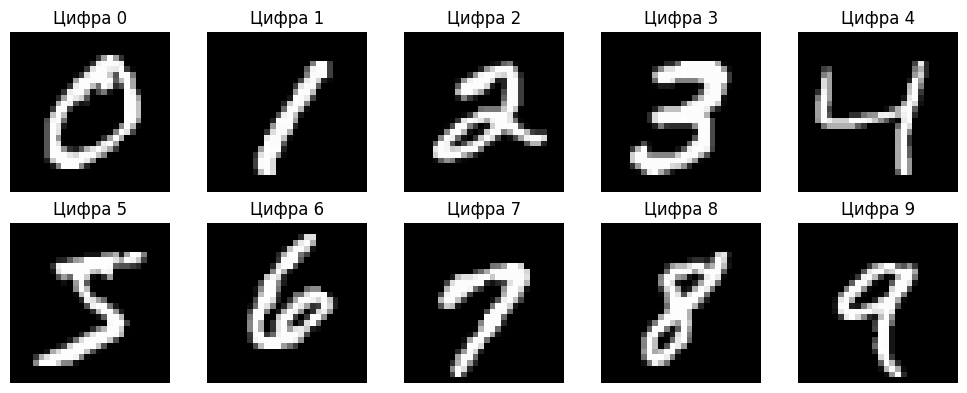

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, axis in enumerate(axes.flat):
    index = np.flatnonzero(labels == digit)[0]
    axis.imshow(images[index], cmap="gray", vmin=0, vmax=255)
    axis.set_title(f"Цифра {digit}")
    axis.axis("off")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "dataset_examples.png", dpi=150)
plt.show()


## 4. Диапазон значений, пропуски и повторы

Проверяем фактические данные. Точный повтор означает полное совпадение всех пикселей изображения.


In [5]:
display(pd.DataFrame([
    {"Показатель": "Изображений", "Значение": len(images)},
    {"Показатель": "Минимальный пиксель", "Значение": int(images.min())},
    {"Показатель": "Максимальный пиксель", "Значение": int(images.max())},
    {"Показатель": "Пропуски и бесконечности", "Значение": int(np.count_nonzero(~np.isfinite(images)))},
    {"Показатель": "Точные повторы", "Значение": len(images) - len(np.unique(images.reshape(len(images), -1), axis=0))},
]))


,Показатель,Значение
0,Изображений,70000
1,Минимальный пиксель,0
2,Максимальный пиксель,255
3,Пропуски и бесконечности,0
4,Точные повторы,0


## 5. Распределение классов



,Цифра,Изображений,"Доля, %"
0,0,6903,9.86
1,1,7877,11.25
2,2,6990,9.99
3,3,7141,10.20
4,4,6824,9.75
5,5,6313,9.02
6,6,6876,9.82
7,7,7293,10.42
8,8,6825,9.75
9,9,6958,9.94


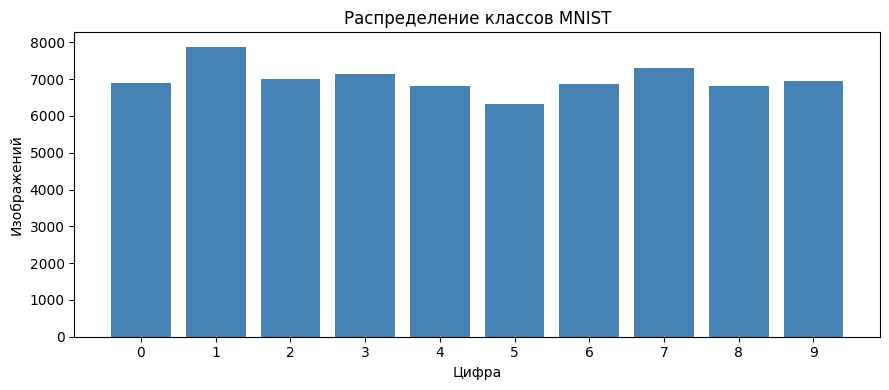

In [6]:
counts = np.bincount(labels)
distribution = pd.DataFrame({
    "Цифра": np.arange(10),
    "Изображений": counts,
    "Доля, %": (counts / labels.size * 100).round(2),
})
display(distribution)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(distribution["Цифра"], distribution["Изображений"], color="steelblue")
ax.set(xticks=np.arange(10), xlabel="Цифра", ylabel="Изображений",
       title="Распределение классов MNIST")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "class_distribution.png", dpi=150)
plt.show()


## 6. t-SNE до обучения CNN


/Users/mishgan/Desktop/учеба/ai_foundation/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:350: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/mishgan/Desktop/учеба/ai_foundation/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:350: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/mishgan/Desktop/учеба/ai_foundation/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:350: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/mishgan/Desktop/учеба/ai_foundation/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:351: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/mishgan/Desktop/учеба/ai_foundation/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:351: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/mishgan/Desktop/учеба/ai_foundation/.venv/lib/python3.10/site-

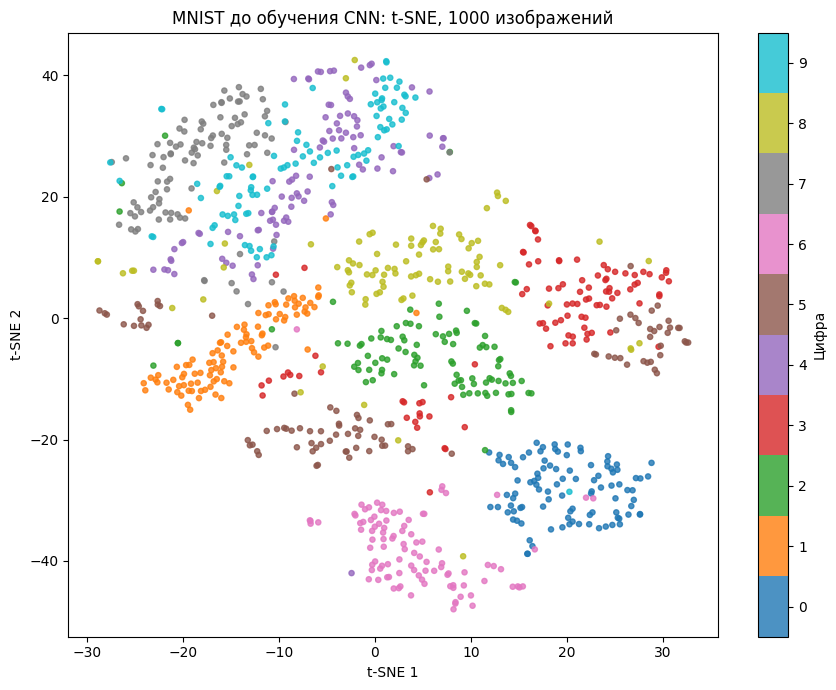

In [7]:
train_images, _, train_labels, _ = train_test_split(
    images, labels, train_size=0.7, random_state=42, stratify=labels,
)
rng = np.random.default_rng(42)
sample_indices = np.concatenate([
    rng.choice(np.flatnonzero(train_labels == digit), size=100, replace=False)
    for digit in range(10)
])
X_tsne = train_images[sample_indices].reshape(1000, -1).astype(np.float32) / 255.0
y_tsne = train_labels[sample_indices]

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate=200,
    max_iter=500,
    init="pca",
    random_state=42,
)
embedding = tsne.fit_transform(X_tsne)

fig, ax = plt.subplots(figsize=(9, 7))
points = ax.scatter(
    embedding[:, 0], embedding[:, 1], c=y_tsne,
    cmap="tab10", vmin=-0.5, vmax=9.5, s=14, alpha=0.8,
)
fig.colorbar(points, ax=ax, ticks=np.arange(10), label="Цифра")
ax.set(xlabel="t-SNE 1", ylabel="t-SNE 2", title="MNIST до обучения CNN: t-SNE, 1000 изображений")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "tsne.png", dpi=150)
plt.show()


## 7. Возможные причины ошибочной классификации

На t-SNE смотрим, какие классы образуют отдельные группы, а какие располагаются рядом или смешиваются.
Проекция строится по исходным пикселям и не использует предсказания CNN.
Перекрытие на плоскости служит подсказкой, но само по себе не доказывает причину ошибки модели.

В последнем выполненном прогоне CNN наиболее частые отдельные ошибки: **4 → 9 — 15 случаев**, **9 → 7 — 12**, **9 → 4 — 10**.
По примерам ниже можно предположить связь ошибок с похожими контурами, незамкнутыми петлями и нестандартным начертанием цифр.
Это наблюдения по уже полученным тестовым предсказаниям, а не результат предварительного t-SNE.

